# 05 — Random-reading sensor faults

**Question.** If failed probes emit *random readings* instead of dropping out, can RobustSHREDv1/v2 still
reconstruct the field, and do they beat SHRED trained with augmentation?

**Setup.** Part 1 uses the trained models from notebook 02 (seeds {0, 1, 2}), evaluation only. Faulty-probe sets are
the cached p = 0.3 test masks (10 draws per test window), with measurement noise as before. Every channel of a faulty
probe is replaced at every lag by garbage ~ N(0.5, 0.5) in the scaled [0, 1] input space (fixed seed, shared by all
methods).

- **garbage_silent**: fault not detected. Mask flags are all zero, so the models read the garbage as valid.
- **garbage_oracle**: fault detected and flagged (masked/flag models and gappy POD only). Masked models ignore
  flagged values, so this equals dropout. SHRED-dropout+mask still sees the garbage values next to the flags
  (it was trained on zero-filled values + flags), so its oracle number is *not* a dropout equivalent.

In [1]:
RUN_EVAL = False   # True: evaluate/train runs not cached yet

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from get_shredded import meeting_plots as mp
from get_shredded.meeting_runner import load_arrays, load_config, load_results
from get_shredded.random_readings import load_rr_arrays, load_rr_results, run_random_readings, train_random_readings

METHODS = ["SHRED-noise", "SHRED-dropout", "SHRED-dropout+mask", "SDN-noise", "SDN-dropout",
           "SenseiverSDN", "RobustSHREDv1", "RobustSHREDv2", "GappyPOD"]
cfg = load_config(["meeting.methods=[" + ",".join(METHODS) + "]"])
ROOT = cfg.outputs.root
RR_ROOT = "outputs/meeting_random_readings"
if RUN_EVAL:
    run_random_readings(cfg)
    train_random_readings(load_config(["meeting.seeds=[0]", f"outputs.root={RR_ROOT}"]))
base = load_results(ROOT)
rr = load_rr_results(ROOT)
trained = load_results(RR_ROOT)
SEEDS = [int(s) for s in cfg.meeting.seeds]
print(f"{len(rr)} random-reading evaluations, {len(trained)} garbage-trained runs")

27 random-reading evaluations, 3 garbage-trained runs


## Part 1: dropout-trained models (mean ± std over seeds)

In [2]:
def stat(vals):
    return (np.mean(vals), np.std(vals)) if vals else (np.nan, np.nan)

COLS = {
    "clean": lambda m, s: base[(m, s)]["metrics"]["clean"]["err"],
    "dropout p0.3": lambda m, s: base[(m, s)]["metrics"]["p0.3"]["err"],
    "garbage silent": lambda m, s: rr[(m, s)]["metrics"]["garbage_silent"]["err"],
    "garbage oracle": lambda m, s: rr[(m, s)]["metrics"].get("garbage_oracle", {}).get("err"),
}
table = {m: {c: stat([v for s in SEEDS if (v := f(m, s)) is not None]) for c, f in COLS.items()} for m in METHODS}
rows = ["| method | " + " | ".join(COLS) + " |", "|---" * (len(COLS) + 1) + "|"]
for m in METHODS:
    rows.append(f"| {m} | " + " | ".join("–" if np.isnan(mu) else f"{mu:.4f} ± {sd:.4f}"
                                         for mu, sd in table[m].values()) + " |")
display(Markdown("\n".join(rows)))

| method | clean | dropout p0.3 | garbage silent | garbage oracle |
|---|---|---|---|---|
| SHRED-noise | 0.0040 ± 0.0006 | 0.1589 ± 0.0062 | 0.1188 ± 0.0075 | – |
| SHRED-dropout | 0.0102 ± 0.0027 | 0.0145 ± 0.0035 | 0.1505 ± 0.0115 | – |
| SHRED-dropout+mask | 0.0099 ± 0.0013 | 0.0113 ± 0.0018 | 0.1084 ± 0.0059 | 0.1281 ± 0.0095 |
| SDN-noise | 0.0040 ± 0.0004 | 0.1803 ± 0.0061 | 0.1679 ± 0.0102 | – |
| SDN-dropout | 0.0101 ± 0.0012 | 0.0243 ± 0.0017 | 0.1900 ± 0.0206 | – |
| SenseiverSDN | 0.0152 ± 0.0017 | 0.0283 ± 0.0046 | 0.1702 ± 0.0169 | 0.0283 ± 0.0046 |
| RobustSHREDv1 | 0.0108 ± 0.0015 | 0.0150 ± 0.0011 | 0.1488 ± 0.0122 | 0.0150 ± 0.0011 |
| RobustSHREDv2 | 0.0094 ± 0.0009 | 0.0151 ± 0.0019 | 0.1411 ± 0.0186 | 0.0151 ± 0.0019 |
| GappyPOD | 0.0007 ± 0.0000 | 0.0916 ± 0.0089 | 0.2349 ± 0.0085 | 0.0916 ± 0.0089 |

**Takeaway:** When faults are silent, every method fails: errors are 0.11–0.19, roughly 10× their dropout errors. RobustSHREDv1/v2 (0.149, 0.141) are no better than SHRED-dropout (0.151) within seed std, and SHRED-noise (0.119) and SHRED-dropout+mask (0.108) are actually lower. Masked attention does not protect against faults it is not told about. When the fault is flagged (oracle), RobustSHREDv1/v2 and SenseiverSDN recover their dropout errors exactly (0.015, 0.015, 0.028). SHRED-dropout+mask does not: given flags but garbage values, it gets 0.128.

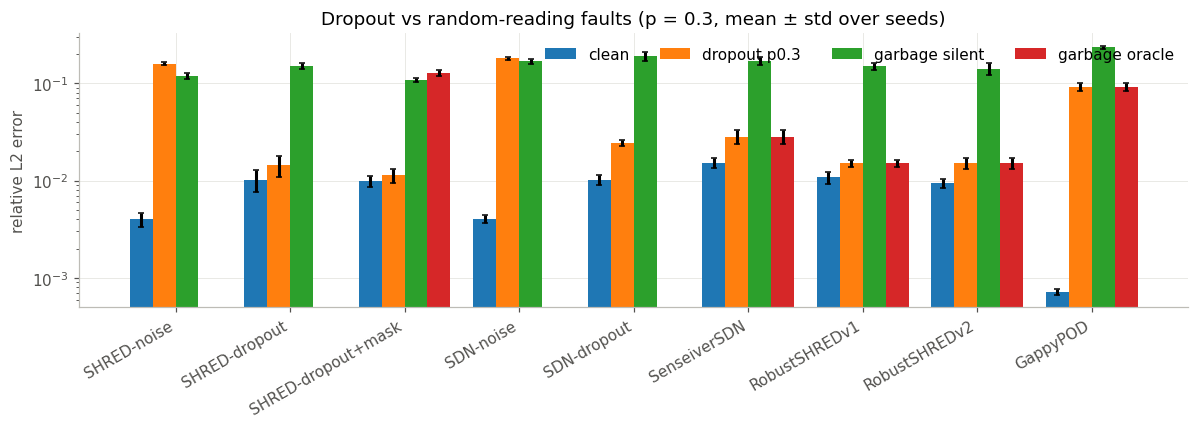

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
width = 0.2
x = np.arange(len(METHODS))
for i, c in enumerate(COLS):
    mu = np.array([table[m][c][0] for m in METHODS]); sd = np.array([table[m][c][1] for m in METHODS])
    ax.bar(x + (i - 1.5) * width, mu, width, yerr=sd, label=c, capsize=2)
ax.set_xticks(x, METHODS, rotation=30, ha="right")
ax.set_yscale("log"); ax.set_ylabel("relative L2 error"); ax.legend(frameon=False, ncol=4)
ax.set_title("Dropout vs random-reading faults (p = 0.3, mean ± std over seeds)")
fig.tight_layout(); mp.save(fig, ROOT, "05_random_readings_bars"); plt.show()

**Takeaway:** On a log scale the silent bars all sit near 0.1–0.2, while dropout and oracle sit near 0.01–0.03 for the dropout-trained models. Gappy POD is hurt most by silent garbage (0.235 vs 0.092 at dropout).

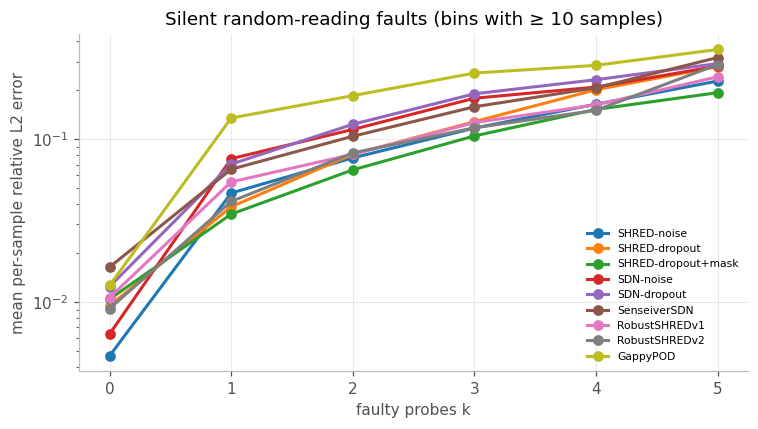

In [4]:
def plot_by_k(ax, err, k, **kw):
    ks = [kk for kk in np.unique(k) if (k == kk).sum() >= 10]
    ax.plot(ks, [err[k == kk].mean() for kk in ks], marker="o", **kw)

fig, ax = plt.subplots(figsize=(7, 4))
for m in METHODS:
    arrs = [load_rr_arrays(ROOT, m, s) for s in SEEDS if (m, s) in rr]
    plot_by_k(ax, np.concatenate([a["garbage_silent_err"] for a in arrs]), np.concatenate([a["k"] for a in arrs]), label=m)
ax.set_yscale("log"); ax.set_xlabel("faulty probes k"); ax.set_ylabel("mean per-sample relative L2 error")
ax.set_title("Silent random-reading faults (bins with ≥ 10 samples)"); ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); mp.save(fig, ROOT, "05_random_readings_by_k"); plt.show()

**Takeaway:** For the networks, silent-fault error grows roughly linearly with k (seed 0: ≈ 0.008 at k = 0, ≈ 0.035 at k = 1, ≈ 0.07–0.085 at k = 2, ≈ 0.11–0.13 at k = 3), and RobustSHRED, SHRED-dropout and SHRED-noise follow nearly the same curve. Gappy POD jumps to ≈ 0.13 at k = 1. The models show no implicit outlier rejection.

## Part 2: models trained on silent random-reading faults (seed 0 only)

SHRED, RobustSHREDv1 and RobustSHREDv2 retrained with the same fault model as the test: 30% of probes fail per
sample, fresh N(0.5, 0.5) garbage per batch, 5% noise, **no failure flags** (the RobustSHREDs get an all-zero mask).
Validation uses a fixed realisation of the same corruption. Same architectures, split, probes and training settings
as notebook 02. Cached in `outputs/meeting_random_readings/seed0/`. Only one seed was run, so there are no error bars.

In [5]:
PAIRS = [("SHRED-dropout", "SHRED-garbage"), ("RobustSHREDv1", "RobustSHREDv1-garbage"),
         ("RobustSHREDv2", "RobustSHREDv2-garbage")]
rows = ["| model | trained on | clean | garbage silent |", "|---|---|---|---|"]
for old, new in PAIRS:
    rows.append(f"| {old} | dropout p=0.3 | {base[(old, 0)]['metrics']['clean']['err']:.4f} | "
                f"{rr[(old, 0)]['metrics']['garbage_silent']['err']:.4f} |")
    m = trained[(new, 0)]["metrics"]
    rows.append(f"| {new} | garbage p=0.3 | {m['clean']['err']:.4f} | {m['garbage_silent']['err']:.4f} |")
display(Markdown("\n".join(rows)))

| model | trained on | clean | garbage silent |
|---|---|---|---|
| SHRED-dropout | dropout p=0.3 | 0.0067 | 0.1596 |
| SHRED-garbage | garbage p=0.3 | 0.0191 | 0.0446 |
| RobustSHREDv1 | dropout p=0.3 | 0.0095 | 0.1387 |
| RobustSHREDv1-garbage | garbage p=0.3 | 0.0216 | 0.0582 |
| RobustSHREDv2 | dropout p=0.3 | 0.0102 | 0.1674 |
| RobustSHREDv2-garbage | garbage p=0.3 | 0.0204 | 0.0313 |

**Takeaway:** Training on the fault model cuts silent-fault error ≈ 3–5× (SHRED 0.160 → 0.045, RobustSHREDv1 0.139 → 0.058, RobustSHREDv2 0.167 → 0.031). Among the garbage-trained models RobustSHREDv2 is lowest and RobustSHREDv1 is above SHRED. That ranking comes from one seed (the meeting runs had seed std ≈ 0.01–0.02). The price is clean error: ≈ 0.02 vs 0.007–0.010 for the dropout-trained models.

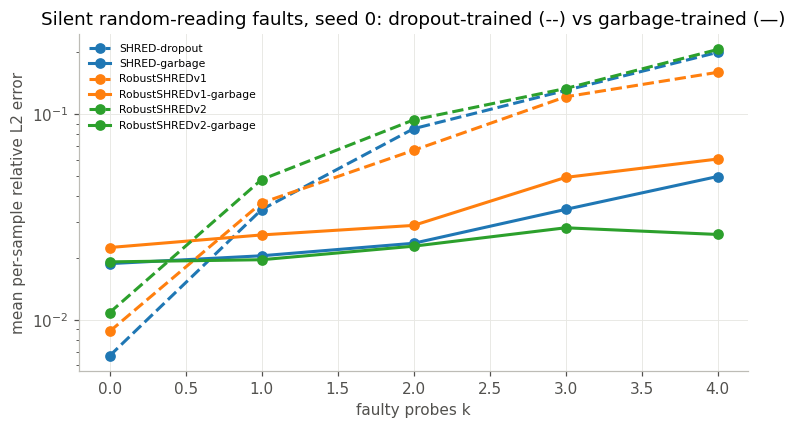

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for i, (old, new) in enumerate(PAIRS):
    a, b = load_rr_arrays(ROOT, old, 0), load_arrays(RR_ROOT, new, 0)
    plot_by_k(ax, a["garbage_silent_err"], a["k"], ls="--", color=f"C{i}", label=old)
    plot_by_k(ax, b["garbage_silent_err"], b["k"], ls="-", color=f"C{i}", label=new)
ax.set_yscale("log"); ax.set_xlabel("faulty probes k"); ax.set_ylabel("mean per-sample relative L2 error")
ax.set_title("Silent random-reading faults, seed 0: dropout-trained (--) vs garbage-trained (—)")
ax.legend(fontsize=7, frameon=False); fig.tight_layout()
mp.save(fig, ROOT, "05_garbage_trained_by_k"); plt.show()

**Takeaway:** RobustSHREDv2-garbage stays almost flat (≈ 0.019 at k = 0 to ≈ 0.026 at k = 4). SHRED-garbage rises to ≈ 0.050 and RobustSHREDv1-garbage to ≈ 0.061 at k = 4. With training, the v2 latent-attention model learns to ignore faulty probes most effectively.

## Conclusion

Without being told which probes failed and without training on this fault type, RobustSHRED is no better than
dropout-trained SHRED (≈ 0.14–0.15). If faults are flagged, RobustSHRED recovers its dropout performance (0.015).
Trained on silent garbage, all three models become robust (0.03–0.06), RobustSHREDv2 most of all, at the cost of
≈ 2–3× higher clean error. The trained comparison is seed 0 only.